In [7]:
## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [224]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm
import math


In [226]:
df = pd.read_csv(lab_amz_uk_processed_data)

df.head()

,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [228]:
df.shape

(2222742, 10)

In [230]:
df.columns.nunique

<bound method IndexOpsMixin.nunique of Index(['asin', 'title', 'imgUrl', 'productURL', 'stars', 'reviews', 'price',
       'isBestSeller', 'boughtInLastMonth', 'categoryName'],
      dtype='object')>

In [232]:
##Crosstab Analysis

In [234]:
cross_tab = pd.crosstab(df['categoryName'], df['isBestSeller'], margins=True)
cross_tab

isBestSeller,False,True,All
categoryName,,,
3D Printers,247,1,248
3D Printing & Scanning,4020,2,4022
Abrasive & Finishing Products,245,5,250
Action Cameras,1014,0,1014
Adapters,248,3,251
...,...,...,...
Window Treatments,234,5,239
Women,16101,183,16284
Women's Sports & Outdoor Shoes,1938,20,1958


In [236]:
cross_tab.dtypes

isBestSeller
False    int64
True     int64
All      int64
dtype: object

In [238]:
cross_tab_prop = cross_tab.copy()
cross_tab_prop['Proportion'] = cross_tab[1] / cross_tab['All']
cross_tab_prop

isBestSeller,False,True,All,Proportion
categoryName,,,,
3D Printers,247,1,248,0.004032
3D Printing & Scanning,4020,2,4022,0.000497
Abrasive & Finishing Products,245,5,250,0.020000
Action Cameras,1014,0,1014,0.000000
Adapters,248,3,251,0.011952
...,...,...,...,...
Window Treatments,234,5,239,0.020921
Women,16101,183,16284,0.011238
Women's Sports & Outdoor Shoes,1938,20,1958,0.010215


In [240]:
cross_tab_prop = cross_tab_prop.sort_values(by='Proportion', ascending= False)
cross_tab_prop

isBestSeller,False,True,All,Proportion
categoryName,,,,
Health & Personal Care,7750,485,8235,0.058895
Grocery,5964,313,6277,0.049865
Mobile Phone Accessories,244,10,254,0.039370
Power & Hand Tools,6212,243,6455,0.037645
"Billiard, Snooker & Pool",241,8,249,0.032129
...,...,...,...,...
Cameras,12,0,12,0.000000
Outdoor Rope Lights,3911,0,3911,0.000000
Computer Cases,222,0,222,0.000000


In [242]:
## Statistical Tests

In [244]:
cross_tab =cross_tab.drop("All", axis=0)

In [246]:
chi2_stat, p_value, _, _ = chi2_contingency(cross_tab)

# Output the results
print(f'Chi-square statistic: {chi2_stat}')
print(f'p-value: {p_value}')


Chi-square statistic: 33019.04971964154
p-value: 0.0


In [248]:
association(cross_tab)

0.0609407453319844

In [250]:
## The Cramer's V value of about 0.061 shows a weak link between the book categories and whether they're bestsellers. In simple terms, the category and bestseller status are not strongly related.

In [252]:
## Visualizations

In [254]:
df2 = cross_tab_prop.drop(columns=["All"])
df_10 = df2.nlargest(11, columns=True).drop(index=["All"]) #Select the top 10 categories
df_10

isBestSeller,False,True,Proportion
categoryName,,,
Health & Personal Care,7750,485,0.058895
Grocery,5964,313,0.049865
Sports & Outdoors,825773,303,0.000367
Pet Supplies,9146,284,0.030117
Power & Hand Tools,6212,243,0.037645
Baby,10645,188,0.017354
Women,16101,183,0.011238
Arts & Crafts,5593,163,0.028318
Men,16237,147,0.008972


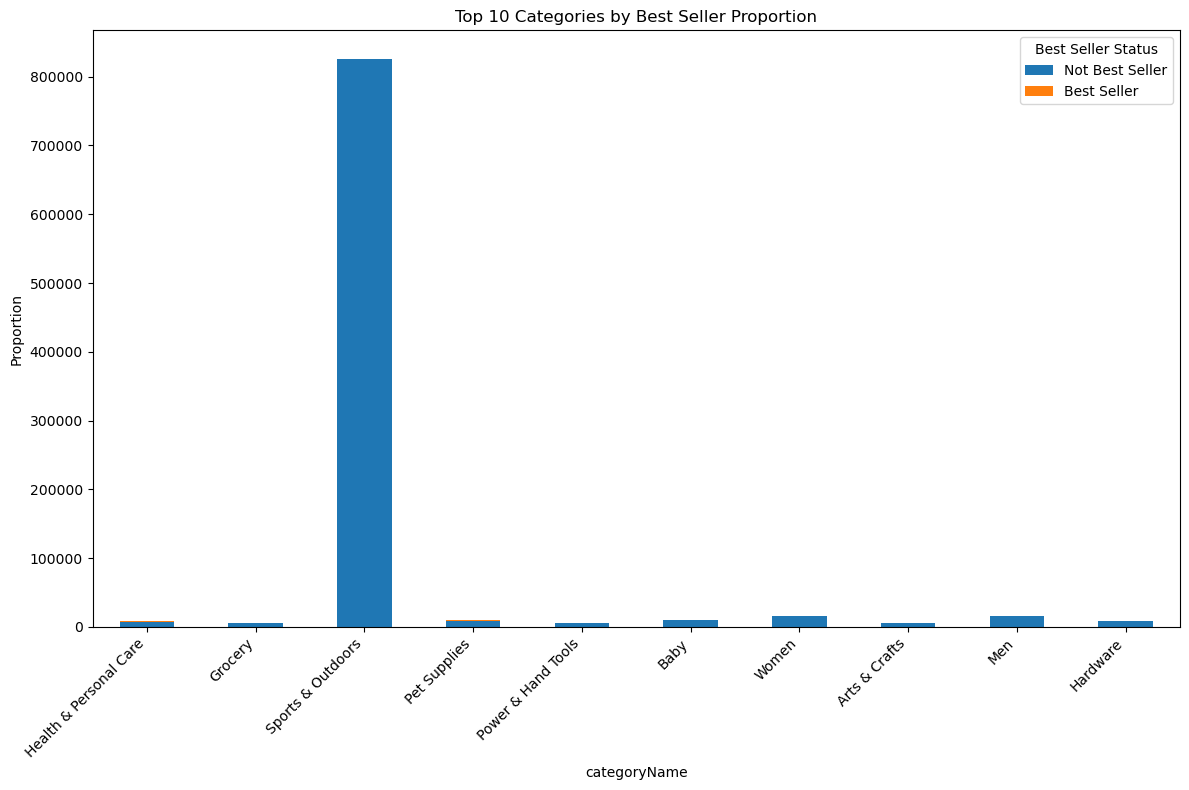

In [256]:
#First Plot: Best Seller Status by 20 Product Category

# Reset index to turn 'categoryName' into a column
df_reset = df_10.reset_index()

# Rename the columns for clarity
df_reset = df_reset.rename(columns={False: 'Not Best Seller', True: 'Best Seller'})

# Select only relevant columns
df_plot = df_reset[['categoryName', 'Not Best Seller', 'Best Seller']]
# Set 'categoryName' as index for plotting
df_plot = df_plot.set_index('categoryName')

# Plot stacked bar chart
ax = df_plot.plot(kind='bar', stacked=True, figsize=(12,8))
plt.xticks(rotation=45, ha='right')
plt.ylabel('Proportion')
plt.title('Top 10 Categories by Best Seller Proportion')
plt.legend(title='Best Seller Status')
plt.tight_layout()
plt.show()

In [258]:
df_drop_sports = df_10.drop(index=["Sports & Outdoors"]) #Both plots, one with this one with hugh quantity respect of the total.
df_drop_sports

isBestSeller,False,True,Proportion
categoryName,,,
Health & Personal Care,7750,485,0.058895
Grocery,5964,313,0.049865
Pet Supplies,9146,284,0.030117
Power & Hand Tools,6212,243,0.037645
Baby,10645,188,0.017354
Women,16101,183,0.011238
Arts & Crafts,5593,163,0.028318
Men,16237,147,0.008972
Hardware,8422,146,0.017040


<Figure size 3000x1500 with 0 Axes>

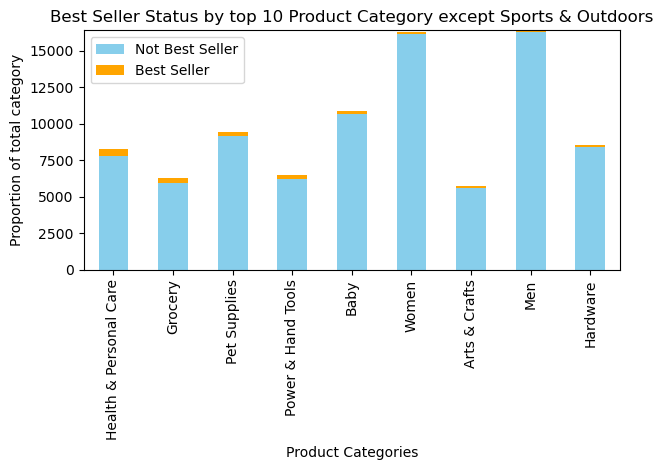

In [260]:
#Second Plot: Best Seller Status by 10 Product Category except Sport & Outdoors Category

plt.figure(figsize=(30, 15))
df_drop_sports.plot(kind='bar', stacked=True, color=['skyblue', 'orange'])
plt.title('Best Seller Status by top 10 Product Category except Sports & Outdoors')
plt.xlabel('Product Categories')
plt.ylabel('Proportion of total category')
plt.xticks(rotation=90)
plt.legend(labels=['Not Best Seller', 'Best Seller'])
plt.tight_layout()
plt.show()

In [262]:
### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

SyntaxError: unterminated string literal (detected at line 13) (3487796835.py, line 13)

In [264]:
## Preliminary Step: Remove outliers in product prices

In [266]:
df["price"].describe().round(2)

count    2222742.00
mean          94.26
std          360.62
min            0.00
25%           10.00
50%           19.90
75%           47.71
max       100000.00
Name: price, dtype: float64

In [268]:
Q1 = np.percentile(df["price"],25)
Q3 = np.percentile(df["price"],75)
IQR = Q3-Q1

In [270]:
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR

In [276]:
df_outliers= df[(df["price"]< lower_bound) | (df["price"]> upper_bound)]
df_outliers.head()

,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
10,B08VDNCZT9,JBL Charge 5 - Portable Bluetooth Speaker with...,https://m.media-amazon.com/images/I/719nhErutk...,https://www.amazon.co.uk/dp/B08VDNCZT9,4.8,11920,139.00,False,0,Hi-Fi Speakers
19,B07NQCKJSH,Echo Studio | Our best-sounding Wi-Fi and Blue...,https://m.media-amazon.com/images/I/91Z0cGhaeC...,https://www.amazon.co.uk/dp/B07NQCKJSH,4.5,14222,164.99,False,0,Hi-Fi Speakers
25,B0BLS36M5R,All-new Echo Show 8 | 3rd generation (2023 rel...,https://m.media-amazon.com/images/I/51dbJ5yt-e...,https://www.amazon.co.uk/dp/B0BLS36M5R,0.0,0,149.99,False,0,Hi-Fi Speakers
28,B096G3R7C3,JBL PartyBox110 Portable Indoor and Outdoor Pa...,https://m.media-amazon.com/images/I/81zdGGRzv9...,https://www.amazon.co.uk/dp/B096G3R7C3,4.8,153,289.00,False,0,Hi-Fi Speakers
31,B08MQRDDYB,"Echo Show 15 | Full HD 15.6"" smart display wit...",https://m.media-amazon.com/images/I/71Aw8DGP6p...,https://www.amazon.co.uk/dp/B08MQRDDYB,4.4,2616,199.99,False,0,Hi-Fi Speakers


In [280]:
df_outliers2 = df[(df["price"]>= lower_bound) & (df["price"]<=upper_bound)]
df_outliers2.head()

,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [282]:
## Violin Plots

In [286]:
top_categories = df_outliers2['categoryName'].value_counts().head(20).index
df2filter = df_outliers2[df_outliers2['categoryName'].isin(top_categories)]

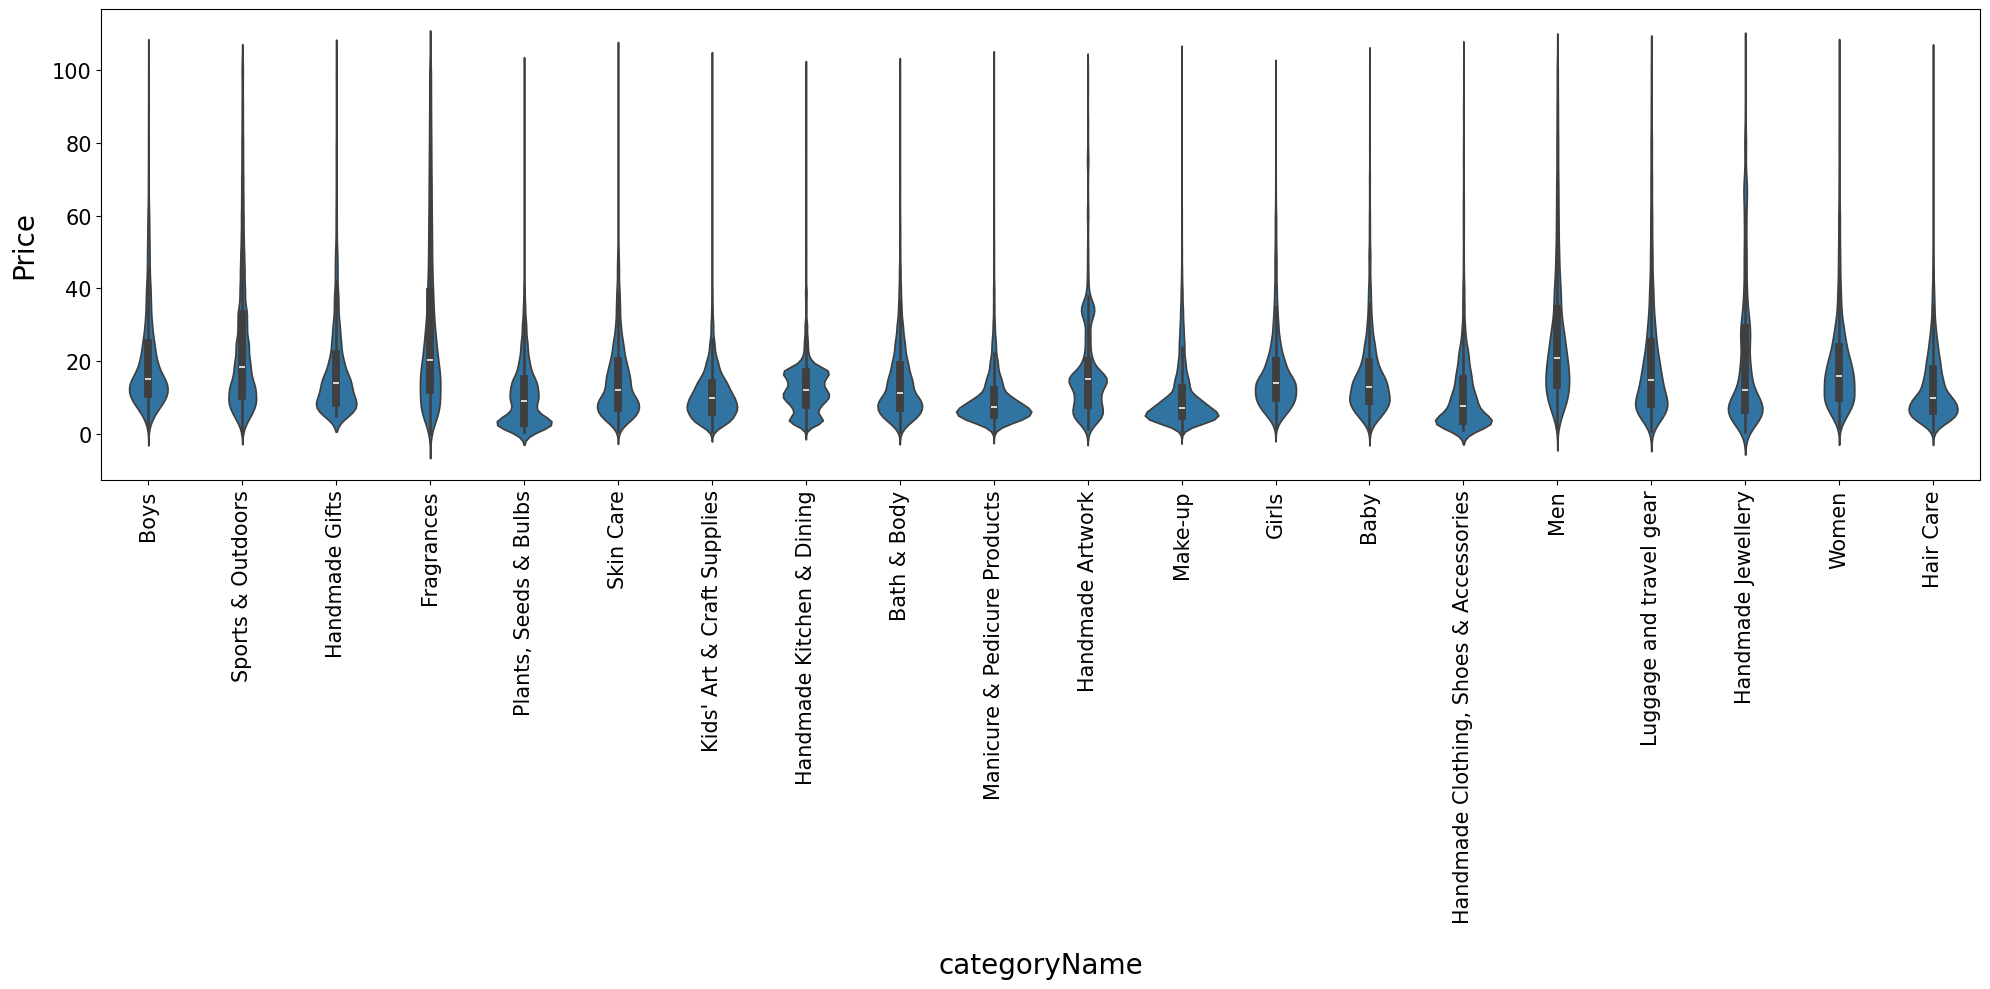

In [288]:
plt.figure(figsize=(20, 10))
sns.violinplot(data=df2filter, x="categoryName", y="price")
plt.xticks(rotation=90, size=15)
plt.yticks(size=15)
plt.xlabel("categoryName", labelpad=20, loc='center', size=20)
plt.ylabel("Price", labelpad=10, loc='center', size=20)
plt.tight_layout()
plt.show()

In [290]:
## Bar Charts

In [292]:
avg_prices =  df_outliers2.groupby("categoryName")["price"].mean().sort_values(ascending=False)
df_avg_prices=pd.DataFrame(avg_prices)
df_avg_prices

,price
categoryName,
Motherboards,70.102078
Tablets,68.737819
Desktop PCs,68.138914
Boxing Shoes,67.811215
Graphics Cards,65.714828
...,...
Bedding Accessories,8.823842
Adapters,8.580000
Arts & Crafts,8.418764


In [294]:
df_categories_count = df_outliers2['categoryName'].value_counts().head(10).sort_values(ascending=False).head(10).reset_index()
df_categories_count

,categoryName,count
0,Sports & Outdoors,688113
1,Skin Care,18678
2,Make-up,18419
3,Fragrances,17530
4,Manicure & Pedicure Products,17179
5,"Handmade Clothing, Shoes & Accessories",16381
6,Women,16063
7,Men,15696
8,Handmade Gifts,15456
9,Bath & Body,14850


In [296]:
df_category_mean = pd.merge(df_categories_count,df_avg_prices, on="categoryName", how="inner")
df_category_mean

,categoryName,count,price
0,Sports & Outdoors,688113,25.292911
1,Skin Care,18678,15.680262
2,Make-up,18419,10.567825
3,Fragrances,17530,28.964164
4,Manicure & Pedicure Products,17179,10.201330
5,"Handmade Clothing, Shoes & Accessories",16381,12.040662
6,Women,16063,20.450253
7,Men,15696,27.226045
8,Handmade Gifts,15456,18.182586
9,Bath & Body,14850,14.577199


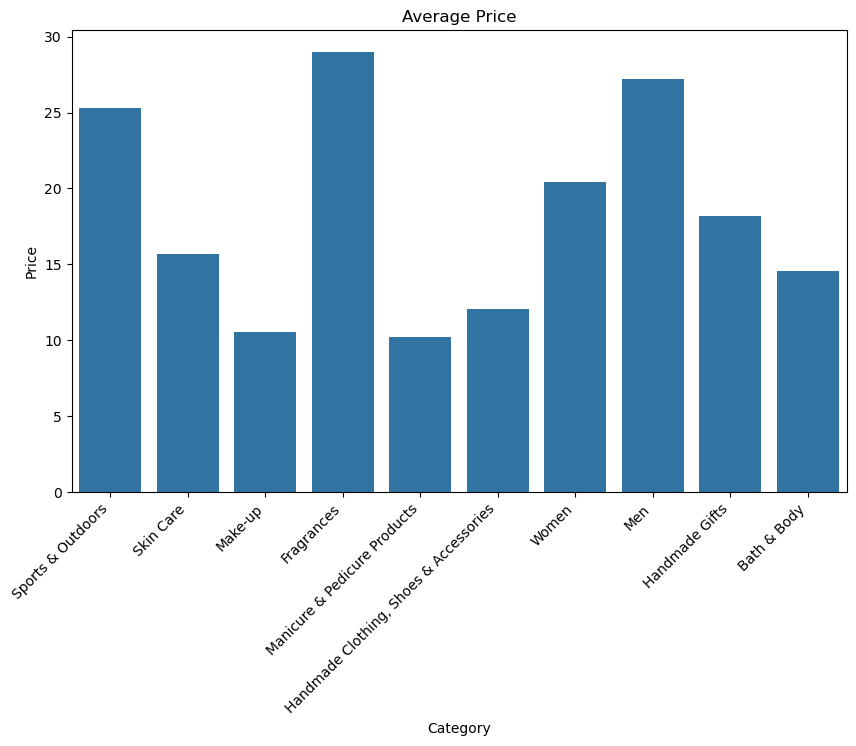

In [298]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_category_mean, x='categoryName', y='price')
plt.xticks(rotation=45, ha='right')  
plt.title('Average Price')
plt.xlabel('Category')
plt.ylabel('Price')
plt.show()

In [ ]:
## Box Plots

In [300]:
dfbox = df[df['stars'].notna()] #Filter without NaN => 0 stars it means 
top_10_categories = dfbox['categoryName'].value_counts().nlargest(10).index
df_top_10 = dfbox[dfbox['categoryName'].isin(top_10_categories)]

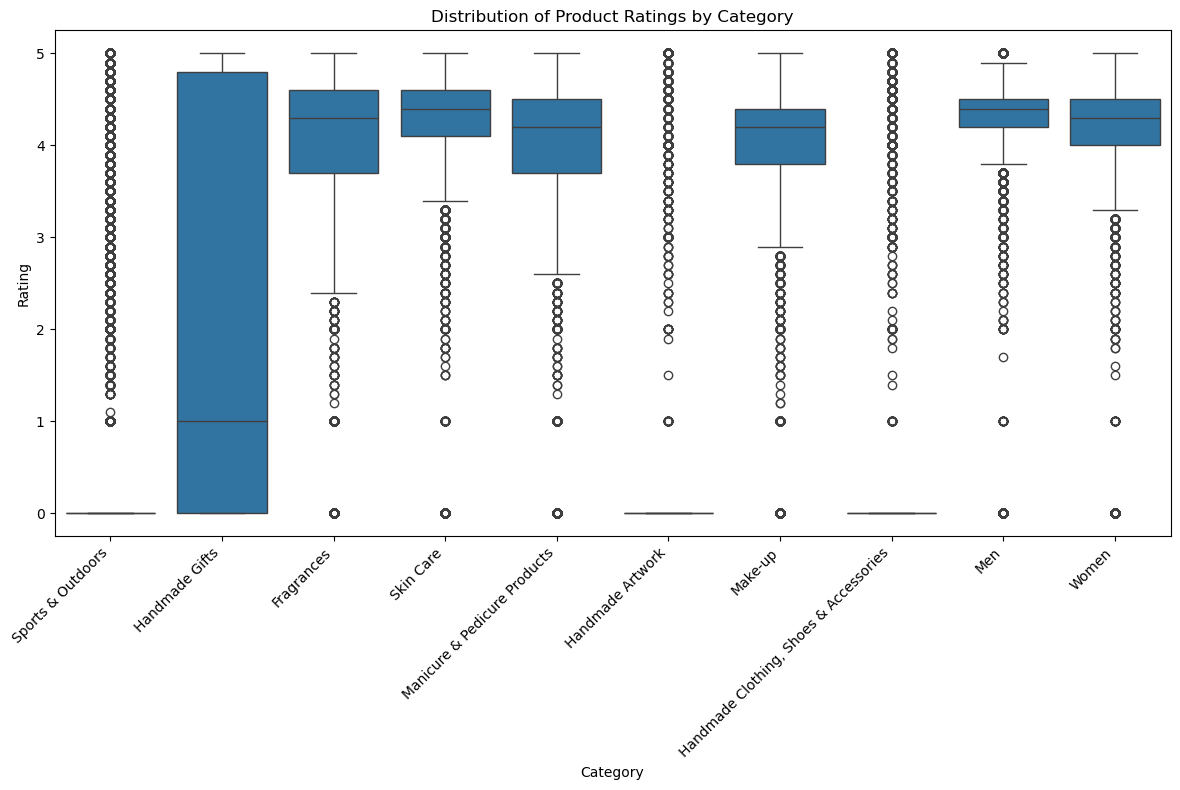

In [302]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_top_10, x='categoryName', y='stars')
plt.title('Distribution of Product Ratings by Category')
plt.xlabel('Category')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?


In [306]:
correlation_price_stars = dfbox['stars'].corr(dfbox['price'])

# Print the correlation coefficient
print(f"The correlation coefficient between product price and rating is: {correlation_price_stars:.2f}")

# Interpret the correlation
if correlation_price_stars > 0:
    print("There is a positive relationship between price and rating.")
elif correlation_price_stars < 0:
    print("There is a negative relationship between price and rating.")
else:
    print("There is no relationship between price and rating.")

The correlation coefficient between product price and rating is: -0.12
There is a negative relationship between price and rating.


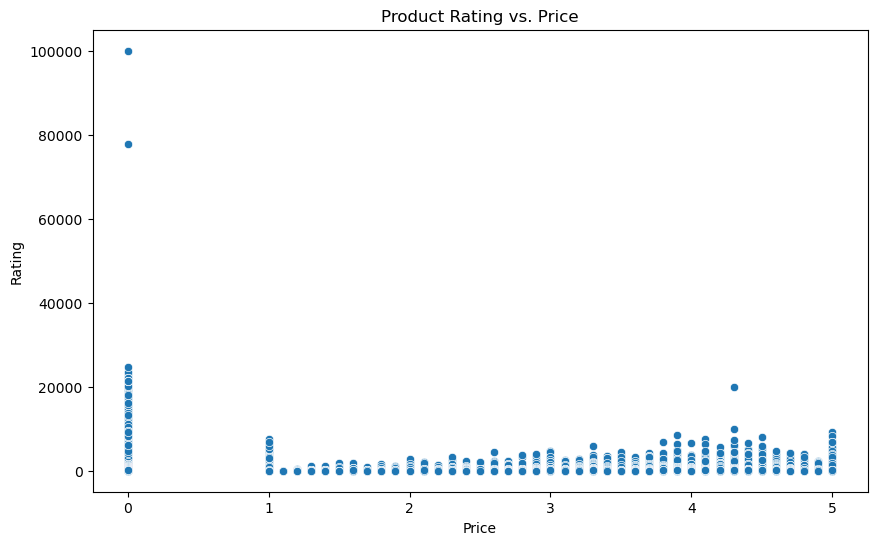

In [308]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=dfbox, x='stars', y='price')
plt.title('Product Rating vs. Price')
plt.xlabel('Price')
plt.ylabel('Rating')
plt.show()

In [310]:
## Products that do receive ratings are typically inexpensive, with most ratings falling between 3.5 and 4.5 stars. Overall, many products are not rated at all.

In [314]:
correlation_price_stars_matrix = dfbox[["price", "stars", "reviews","boughtInLastMonth"]].corr()

In [316]:
mask = np.triu(np.ones_like(correlation_price_stars_matrix, dtype=bool)) 

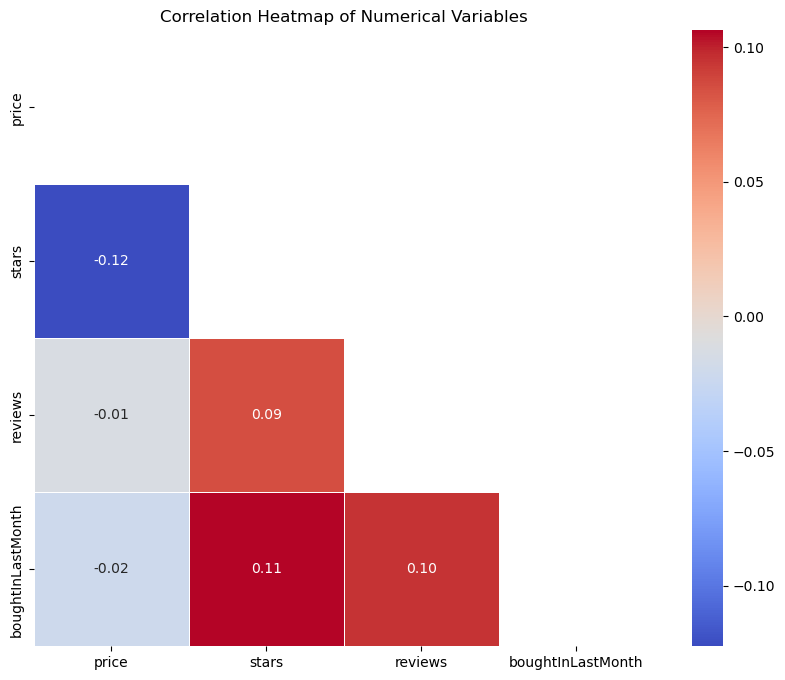

In [318]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_price_stars_matrix , annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, mask=mask)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

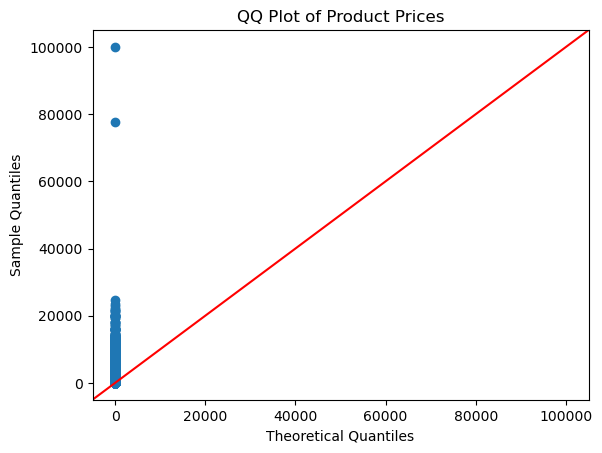

In [326]:
sm.qqplot(dfbox['price'], line ='45')
plt.title('QQ Plot of Product Prices')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.show()